# **Overlay**

<!-- Oscar writes this -->

This part of the book concerns calendar overlays. These, very loosely, are signals which act under certain market conditions, at certain calendar times, and move capital into different assets. This notebook concerns the cumulative overlay, similarly to the sleeves.

## Imports

In [1]:
import sys
from pathlib import Path
here = Path.cwd()
src = next(c for p in [here, *here.parents]
           for c in (p / "src", p / "isa_showcase" / "src", p / "isa_portfolio" / "isa_showcase" / "src",
                     p / "trading_portfolio" / "isa_portfolio" / "isa_showcase" / "src")
           if (c / "showcase_plots.py").exists())
sys.path.insert(0, str(src))
import pandas as pd
import showcase_plots as sp
sp.style()
d = sp.monthly()

## Contribution

Similarly to other notebooks, begin by showing the contribution the overlays have to the book.

In [2]:
sp.table("parts_stats.csv").query("part == 'overlay'").drop(columns="part").set_index("window")

,months,mean_pp_per_year,vol_pp_per_year,sharpe_of_contribution,best_month_pp,worst_month_pp,sum_pp,correlation_with_core
window,,,,,,,,
full 2001-02–2026-09,308,0.947,1.944,0.487,6.248,-2.439,24.298,-0.088
book 2006-01–2026-09,249,1.171,2.158,0.543,6.248,-2.439,24.298,-0.108
2001-05,59,0.000,0.000,NaN,0.000,0.000,0.000,NaN
2006-13,96,1.115,1.550,0.719,2.198,-0.924,8.923,-0.060
2014-19,72,0.584,1.778,0.329,1.295,-2.439,3.506,-0.197
2020-26,81,1.758,2.952,0.596,6.248,-1.711,11.868,-0.111


It is easy to see that the overlay is positive over every extended time period, and contributes noticable Sharpe to the book

## Cumulative contribution

<!-- Oscar writes this -->

Below, see the plot that shows the cumulative monthly contribution of the overlays as a function of time

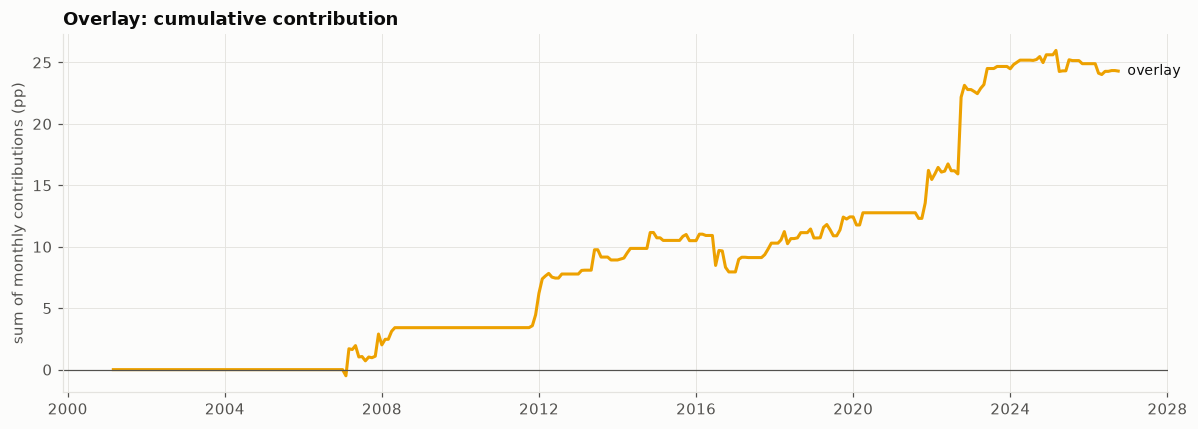

In [3]:
sp.lines({"overlay": 100 * d["overlay"].cumsum()}, sp.COLORS, "Overlay: cumulative contribution", "sum of monthly contributions (pp)")

It is easy to see that, the cumulative overlay is usually positive on its trades, and the main negative trades occur in 2016. This same pattern can be seen in the yearly distrubution below.

## By year


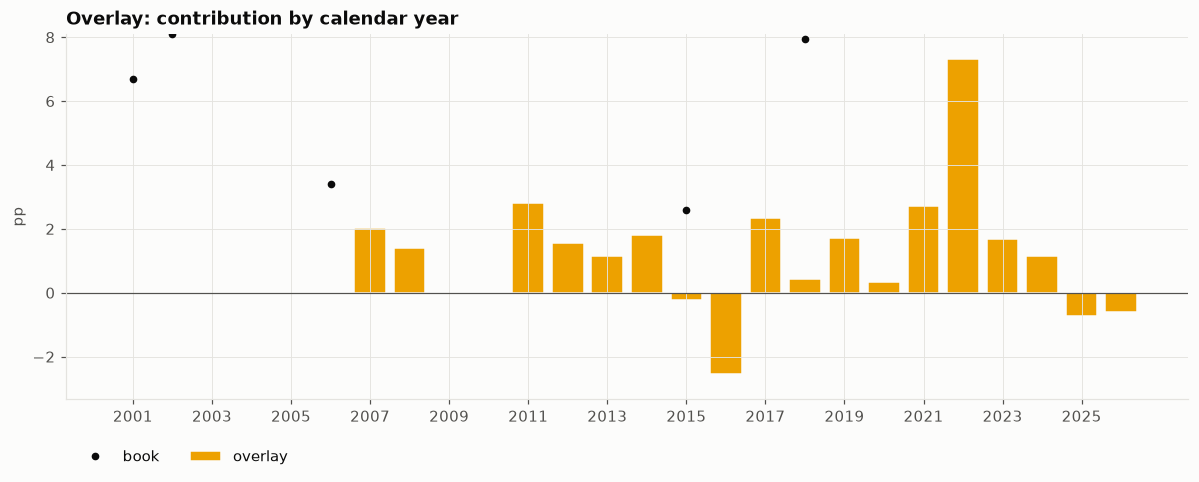

In [4]:
y = sp.table("parts_by_year.csv").set_index("year").rename(columns=lambda c: c.removesuffix("_pp"))
sp.year_bars(y, ["overlay"], "Overlay: contribution by calendar year", "pp")

The overlay adds to the book except for primarily in 2016, where upon further investigation, there was a few bad trades surrounding the Brexit incident.